# RNN Next-Word Prediction with PyTorch

## Notebook trình diễn kỹ thuật

Notebook này xây dựng bài toán **dự đoán từ tiếp theo** bằng Recurrent Neural Network (RNN) với PyTorch. Mục tiêu là tạo một demo đủ thực tế để thuyết trình: người dùng nhập seed text, model tạo probability distribution trên vocabulary và trả về các candidate tiếp theo.

```text
Raw text → tokenization → vocabulary → token IDs
        → sequences → Embedding → RNN → Linear
        → vocabulary logits → probability distribution
        → next-word prediction
```

Notebook dùng **PyTorch + CPU**. Dataset là **WikiText-103 word-level**, một corpus language-modeling lớn do Salesforce AI Research phát hành. Bản word-level có kích thước download khoảng 181 MB và WikiText-103 chứa hơn 100 triệu tokens theo mô tả của nguồn phát hành.

Mục tiêu học tập:

- hiểu sequential data và hidden state;
- hiểu công thức recurrent update;
- hiểu embedding và tensor shape;
- xây dựng shifted input/target cho next-word prediction;
- hiểu CrossEntropyLoss, BPTT và gradient clipping;
- đánh giá bằng loss, perplexity, Top-1 và Top-5 accuracy;
- demo top-k prediction;
- quan sát ảnh hưởng của temperature;
- sinh tiếp văn bản theo autoregressive generation.

## Mục lục

1. Project setup
2. Dataset source and provenance
3. Reproducibility and hyperparameters
4. Download and audit corpus
5. Vocabulary and encoding
6. Sequence construction
7. RNN fundamentals
8. Tensor shapes
9. PyTorch model
10. Training objective
11. BPTT and gradient clipping
12. Training loop and checkpointing
13. Training visualization
14. Test metrics
15. Next-word prediction
16. Temperature
17. Autoregressive generation
18. Strengths and limitations
19. LSTM/GRU motivation
20. Final summary
21. References

# Phần A — Thiết lập dự án

## 1. Folder structure

```text
RNN demo/
├── notebooks/
│   └── RNN_Next_Word_Prediction_PyTorch.ipynb
├── data/
│   └── wikitext103/
├── models/
└── outputs/
    ├── figures/
    ├── metrics/
    └── predictions/
```

Mục đích của việc tách thư mục là để raw data, model artifact và kết quả đánh giá không bị trộn lẫn. Model sau khi train có thể được load lại cho web demo mà không cần train lại.

In [23]:
# Mục đích: Import thư viện và tạo các thư mục dùng chung cho notebook.
from pathlib import Path
from collections import Counter
import json
import math
import random
import time
import urllib.request
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

current = Path.cwd()
PROJECT_ROOT = current
for candidate in [current, current.parent, current.parent.parent]:
    if (candidate / "data").exists():
        PROJECT_ROOT = candidate
        break

DATA_DIR = PROJECT_ROOT / "data" / "wikitext103"
MODELS_DIR = PROJECT_ROOT / "models"
OUTPUTS_DIR = PROJECT_ROOT / "outputs"
FIGURES_DIR = OUTPUTS_DIR / "figures"
METRICS_DIR = OUTPUTS_DIR / "metrics"
PREDICTIONS_DIR = OUTPUTS_DIR / "predictions"

for folder in [DATA_DIR, MODELS_DIR, FIGURES_DIR, METRICS_DIR, PREDICTIONS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("PyTorch:", torch.__version__)
print("Project root:", PROJECT_ROOT)

PyTorch: 2.14.0+cpu
Project root: C:\Users\ADMIN\Downloads\Intelligent System\RNN\DATA\Not Plus


## 2. Dataset source and provenance

### WikiText-103

**Primary source:** Salesforce AI Research — *The WikiText Long Term Dependency Language Modeling Dataset*

https://www.salesforce.com/blog/the-wikitext-long-term-dependency-language-modeling-dataset/

**Dataset repository:**
https://huggingface.co/datasets/Salesforce/wikitext

WikiText được xây dựng từ các bài Wikipedia được tuyển chọn và cung cấp các split train, validation và test. WikiText-103 có hơn 100 triệu tokens và bản word-level có kích thước download khoảng 181 MB.

Dataset này phù hợp với next-word prediction vì mỗi sample là một sequence ngôn ngữ tự nhiên và mục tiêu có thể được đặt thành dự đoán token tiếp theo.

### Tại sao chỉ train một subset trên CPU?

Full corpus đủ lớn để làm thí nghiệm thực tế nhưng train toàn bộ hơn 100 triệu tokens với vanilla RNN trên CPU sẽ rất nặng. Vì vậy notebook **tải dataset gốc**, sau đó giới hạn số token được sử dụng cho experiment.

## 3. Reproducibility and hyperparameters

Các tham số chính được cố định để notebook dễ chạy lại:

| Parameter | Value | Purpose |
|---|---:|---|
| Sequence length | 32 | Số context positions trong mỗi sample |
| Vocabulary | 75,000 | Giới hạn số class output |
| Embedding dim | 128 | Kích thước vector mỗi token |
| Hidden size | 192 | Kích thước hidden state |
| RNN layers | 1 | Giữ kiến trúc đơn giản và CPU-friendly |
| Batch size | 64 | Số sequence mỗi optimizer step |
| Learning rate | 0.001 | Bước cập nhật Adam |
| Dropout | 0.20 | Regularization sau RNN |
| Max epochs | 5 | Giới hạn training time |
| Gradient clip | 1.0 | Giảm exploding gradients |

`SEQ_LEN` càng lớn thì model có nhiều context hơn nhưng BPTT dài hơn. `HIDDEN_SIZE` lớn hơn tăng capacity nhưng cũng tăng computation. `VOCAB_SIZE` đặc biệt quan trọng vì nó làm embedding và output classifier lớn lên.

In [24]:
# Mục đích: Thiết lập seed và hyperparameters cho experiment CPU.
SEED = 42
SEQ_LEN = 32
VOCAB_SIZE = 75_000
EMBED_DIM = 128
HIDDEN_SIZE = 192
NUM_LAYERS = 1
DROPOUT = 0.20
BATCH_SIZE = 64
LEARNING_RATE = 1e-3
MAX_EPOCHS = 5
GRAD_CLIP = 1.0
PATIENCE = 2

# Giới hạn token chỉ để kiểm soát computational cost trên CPU.
MAX_TRAIN_TOKENS = 2_000_000
MAX_VALID_TOKENS = 200_000
MAX_TEST_TOKENS = 200_000

DEVICE = torch.device("cpu")
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("Device:", DEVICE)
print("Train token limit:", MAX_TRAIN_TOKENS)

Device: cpu
Train token limit: 2000000


# Phần B — Chuẩn bị dữ liệu văn bản

## 4. Download and audit WikiText-103

Archive chính thức chứa `wiki.train.tokens`, `wiki.valid.tokens` và `wiki.test.tokens`. Notebook giữ nguyên ba split và chỉ thêm `<eos>` ở cuối mỗi dòng để biểu diễn boundary.

Trước training cần kiểm tra kích thước file, số tokens, số unique tokens và frequency. Đây là bước data audit cơ bản chứ không phải phần phụ. Với NLP, frequency distribution ảnh hưởng trực tiếp đến vocabulary và output-space.

In [25]:
# Mục đích:
# Tải WikiText-103 từ nguồn dữ liệu hiện tại và chuẩn hóa thành 3 file text:
# wiki.train.tokens, wiki.valid.tokens, wiki.test.tokens.
#
# Vì URL S3 cũ có thể trả về HTTP 301, cell này không còn phụ thuộc trực tiếp
# vào urllib.request.urlretrieve() của URL cũ.

from pathlib import Path
import urllib.request
import zipfile
import shutil


# Mục đích:
# Khai báo thư mục và các file đầu ra để toàn bộ notebook sử dụng cùng một vị trí dữ liệu.
WIKITEXT_DIR = DATA_DIR / "wikitext-103"
WIKITEXT_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_PATH = WIKITEXT_DIR / "wiki.train.tokens"
VALID_PATH = WIKITEXT_DIR / "wiki.valid.tokens"
TEST_PATH = WIKITEXT_DIR / "wiki.test.tokens"

# Hugging Face cung cấp bộ WikiText-103 hiện tại dưới dạng dataset.
HF_DATASET_PAGE = "https://huggingface.co/datasets/Salesforce/wikitext"


def download_wikitext103_from_huggingface():
    """
    Mục đích:
        Tải WikiText-103 từ Hugging Face thông qua thư viện `datasets`.

    Giá trị trả về:
        dict:
            Dictionary chứa ba tập dữ liệu train, validation và test.
    """
    try:
        # Import tại đây để notebook chỉ yêu cầu thư viện khi thực sự cần tải dataset.
        from datasets import load_dataset
    except ImportError as exc:
        raise ImportError(
            "Chưa cài thư viện `datasets`.\n"
            "Hãy chạy:\n"
            "pip install datasets"
        ) from exc

    print("Đang tải WikiText-103 từ Hugging Face...")
    print("Nguồn:", HF_DATASET_PAGE)

    # `Salesforce/wikitext` là dataset chính thức được duy trì trên Hugging Face.
    # `wikitext-103-v1` là cấu hình word-level phù hợp với bài toán dự đoán từ tiếp theo.
    dataset = load_dataset(
        "Salesforce/wikitext",
        "wikitext-103-v1",
    )

    return dataset


def save_wikitext_splits(dataset):
    """
    Mục đích:
        Ghi các split của WikiText-103 thành các file `.tokens`
        để phần preprocessing phía sau có thể đọc bằng Python thông thường.

    Tham số:
        dataset:
            DatasetDict chứa các split train, validation và test.

    Giá trị trả về:
        dict:
            Đường dẫn tới ba file token đã được tạo.
    """
    split_mapping = {
        "train": TRAIN_PATH,
        "validation": VALID_PATH,
        "test": TEST_PATH,
    }

    for split_name, output_path in split_mapping.items():
        print(f"\nĐang ghi split: {split_name}")

        # Mở file UTF-8 để giữ nguyên ký tự văn bản của corpus.
        with open(output_path, "w", encoding="utf-8") as file:
            for row in dataset[split_name]:
                text = row["text"]

                # Mỗi sample của WikiText là một dòng văn bản.
                file.write(text.rstrip("\n") + "\n")

        print(
            f"Đã lưu: {output_path} "
            f"({output_path.stat().st_size / (1024**2):.2f} MB)"
        )

    return split_mapping


def prepare_wikitext103():
    """
    Mục đích:
        Chuẩn bị hoàn chỉnh WikiText-103 cho notebook.

        Nếu ba file `.tokens` đã tồn tại, hàm sẽ sử dụng lại dữ liệu local
        và không tải lại dataset.

    Giá trị trả về:
        dict:
            Đường dẫn tới train, validation và test files.
    """
    # Nếu dữ liệu local đã tồn tại đầy đủ thì không cần tải lại.
    if TRAIN_PATH.exists() and VALID_PATH.exists() and TEST_PATH.exists():
        print("WikiText-103 đã tồn tại local. Không cần tải lại.")

        return {
            "train": TRAIN_PATH,
            "valid": VALID_PATH,
            "test": TEST_PATH,
        }

    # Tải dataset từ Hugging Face.
    dataset = download_wikitext103_from_huggingface()

    # Chuyển dataset về dạng `.tokens` quen thuộc với pipeline hiện tại.
    paths = save_wikitext_splits(dataset)

    return {
        "train": paths["train"],
        "valid": paths["validation"],
        "test": paths["test"],
    }


# Mục đích:
# Thực hiện toàn bộ quy trình chuẩn bị dữ liệu và kiểm tra kết quả cuối cùng.
paths = prepare_wikitext103()

print("\n" + "=" * 60)
print("WikiText-103 files")
print("=" * 60)

for split, path in paths.items():
    if path.exists():
        size_mb = path.stat().st_size / (1024**2)
        print(f"{split:>5}: {path} | {size_mb:.2f} MB")
    else:
        print(f"{split:>5}: MISSING -> {path}")

WikiText-103 đã tồn tại local. Không cần tải lại.

WikiText-103 files
train: C:\Users\ADMIN\Downloads\Intelligent System\RNN\DATA\Not Plus\data\wikitext103\wikitext-103\wiki.train.tokens | 515.34 MB
valid: C:\Users\ADMIN\Downloads\Intelligent System\RNN\DATA\Not Plus\data\wikitext103\wikitext-103\wiki.valid.tokens | 1.09 MB
 test: C:\Users\ADMIN\Downloads\Intelligent System\RNN\DATA\Not Plus\data\wikitext103\wikitext-103\wiki.test.tokens | 1.22 MB


In [26]:
# Mục đích: Đọc token stream theo word-level WikiText và thêm token <eos>.
def read_wikitext_tokens(path, max_tokens=None):
    """
    Mục đích:
        Chuyển file WikiText word-level thành danh sách token.

    Tham số:
        path (Path): File dữ liệu.
        max_tokens (int|None): Giới hạn token cho CPU experiment.

    Giá trị trả về:
        list[str]: Token sequence.
    """
    tokens = []
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            tokens.extend(line.split())
            tokens.append("<eos>")
            if max_tokens is not None and len(tokens) >= max_tokens:
                return tokens[:max_tokens]
    return tokens

train_tokens = read_wikitext_tokens(paths["train"], MAX_TRAIN_TOKENS)
valid_tokens = read_wikitext_tokens(paths["valid"], MAX_VALID_TOKENS)
test_tokens = read_wikitext_tokens(paths["test"], MAX_TEST_TOKENS)

print("Train:", len(train_tokens))
print("Validation:", len(valid_tokens))
print("Test:", len(test_tokens))
print(train_tokens[:60])

Train: 2000000
Validation: 200000
Test: 200000
['=', 'Valkyria', 'Chronicles', 'III', '=', '<eos>', 'Senjō', 'no', 'Valkyria', '3', ':', '<unk>', 'Chronicles', '(', 'Japanese', ':', '戦場のヴァルキュリア3', ',', 'lit', '.', 'Valkyria', 'of', 'the', 'Battlefield', '3', ')', ',', 'commonly', 'referred', 'to', 'as', 'Valkyria', 'Chronicles', 'III', 'outside', 'Japan', ',', 'is', 'a', 'tactical', 'role', '@-@', 'playing', 'video', 'game', 'developed', 'by', 'Sega', 'and', 'Media.Vision', 'for', 'the', 'PlayStation', 'Portable', '.', 'Released', 'in', 'January', '2011', 'in']


In [27]:
# Mục đích: Tóm tắt frequency distribution và những token xuất hiện nhiều nhất.
def audit_tokens(tokens, split_name, top_n=20):
    """
    Mục đích:
        Kiểm tra kích thước và đặc điểm frequency của token stream.
    """
    counts = Counter(tokens)
    print(f"--- {split_name} ---")
    print("Total tokens:", len(tokens))
    print("Unique tokens:", len(counts))
    print("<eos> count:", counts.get("<eos>", 0))
    return pd.DataFrame(counts.most_common(top_n), columns=["token", "count"])

train_freq = audit_tokens(train_tokens, "Train")
valid_freq = audit_tokens(valid_tokens, "Validation")
test_freq = audit_tokens(test_tokens, "Test")
display(train_freq)

--- Train ---
Total tokens: 2000000
Unique tokens: 65997
<eos> count: 22890
--- Validation ---
Total tokens: 200000
Unique tokens: 17875
<eos> count: 2283
--- Test ---
Total tokens: 200000
Unique tokens: 17353
<eos> count: 2275


,token,count
0,the,109240
1,",",96219
2,.,70691
3,of,54572
4,and,48622
5,in,38066
6,to,37826
7,a,32933
8,=,28480
9,"""",27566


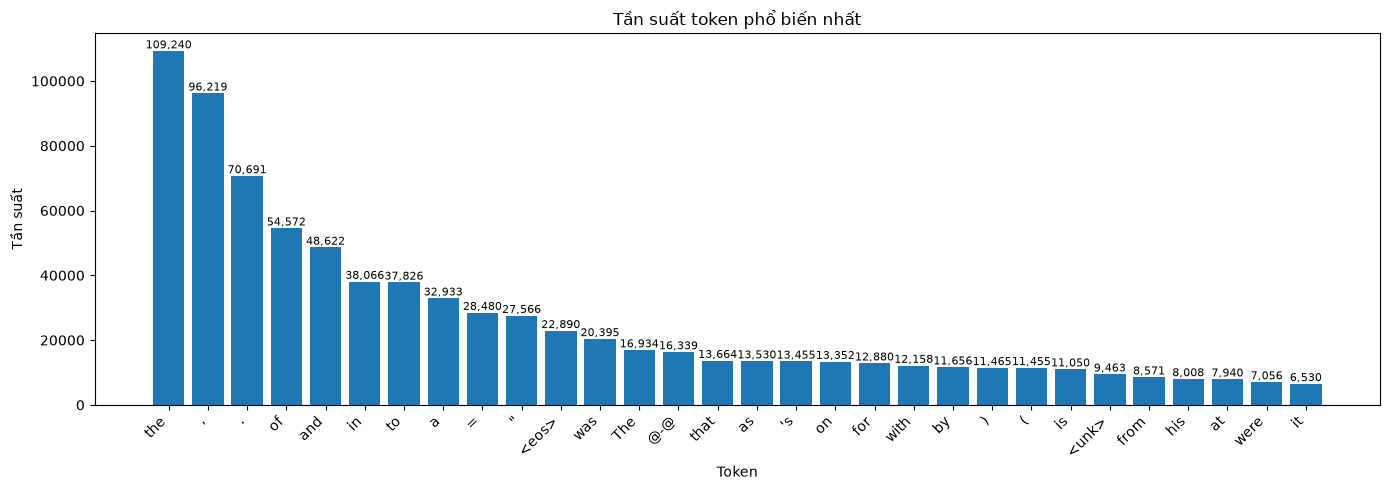

In [28]:
# Mục đích: Visualize top token frequencies và minh họa long-tail distribution.
def plot_token_frequency(tokens, top_n=30):
    """Mục đích: Vẽ frequency của top-N tokens để hỗ trợ data analysis."""
    pairs = Counter(tokens).most_common(top_n)
    words = [x[0] for x in pairs]
    values = [x[1] for x in pairs]
    plt.figure(figsize=(14,5))
    bars = plt.bar(words, values)
    for bar, value in zip(bars, values):
        # Ghi exact count để chart có thể đưa vào báo cáo.
        plt.text(bar.get_x()+bar.get_width()/2, bar.get_height(), f"{value:,}", ha="center", va="bottom", fontsize=8)
    plt.title("Tần suất token phổ biến nhất")
    plt.xlabel("Token"); plt.ylabel("Tần suất")
    plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()
plot_token_frequency(train_tokens)

## 5. Vocabulary and integer encoding

RNN nhận tensor số, không nhận string. Vì vậy ta tạo:

```text
word → ID → embedding vector
```

Vocabulary chỉ được xây từ **training split**. Token ngoài top 75,000 được đưa về `<unk>`.

Tỷ lệ `<unk>` phải được báo cáo vì nó cho biết bao nhiêu token trong validation/test không có class riêng trong vocabulary.

In [29]:
# Mục đích: Xây vocabulary từ train và mã hóa ba split.
SPECIAL_TOKENS = ["<unk>", "<eos>"]

def build_vocabulary(tokens, vocab_size):
    """
    Mục đích:
        Tạo token_to_id và id_to_token từ training corpus.

    Tham số:
        tokens: Training tokens.
        vocab_size: Số token tối đa.

    Giá trị trả về:
        tuple: token_to_id, id_to_token, Counter.
    """
    counts = Counter(tokens)
    regular = [t for t,_ in counts.most_common() if t not in SPECIAL_TOKENS][:vocab_size-len(SPECIAL_TOKENS)]
    vocab = SPECIAL_TOKENS + regular
    token_to_id = {t:i for i,t in enumerate(vocab)}
    id_to_token = {i:t for t,i in token_to_id.items()}
    return token_to_id, id_to_token, counts

def encode_tokens(tokens, token_to_id):
    """
    Mục đích:
        Chuyển token strings thành integer IDs phục vụ Embedding.
    """
    unk = token_to_id["<unk>"]
    return np.asarray([token_to_id.get(t, unk) for t in tokens], dtype=np.int64)

token_to_id, id_to_token, train_counts = build_vocabulary(train_tokens, VOCAB_SIZE)
train_ids = encode_tokens(train_tokens, token_to_id)
valid_ids = encode_tokens(valid_tokens, token_to_id)
test_ids = encode_tokens(test_tokens, token_to_id)

unk_rates = {
    "train": float(np.mean(train_ids == token_to_id["<unk>"])),
    "validation": float(np.mean(valid_ids == token_to_id["<unk>"])),
    "test": float(np.mean(test_ids == token_to_id["<unk>"]))
}
print("Vocabulary:", len(token_to_id))
print({k:f"{v*100:.2f}%" for k,v in unk_rates.items()})

Vocabulary: 65997
{'train': '0.47%', 'validation': '3.33%', 'test': '3.96%'}


## 6. Sequence construction for next-word prediction

Ví dụ:

```text
Input : the cat sat on the
Target:      cat sat on the mat
```

Tức là target chính là input dịch một token.

Với `SEQ_LEN = 32`:

```text
Input  shape = (32,)
Target shape = (32,)
```

Trong training, mỗi timestep trở thành một next-token classification task. Vì vậy một sequence tạo ra nhiều learning signals.

In [30]:
# Mục đích: Tạo Dataset với shifted target cho language modeling.
class NextWordDataset(Dataset):
    """
    Mục đích:
        Chia token stream thành các sequence cố định và tạo target dịch trái một token.
    """
    def __init__(self, token_ids, seq_len):
        # Chỉ giữ full windows để DataLoader stack được mà không cần padding.
        usable = ((len(token_ids)-1)//seq_len)*seq_len
        self.inputs = torch.tensor(token_ids[:usable], dtype=torch.long).view(-1, seq_len)
        self.targets = torch.tensor(token_ids[1:usable+1], dtype=torch.long).view(-1, seq_len)

    def __len__(self):
        # Trả về số sequence.
        return self.inputs.size(0)

    def __getitem__(self, index):
        # Trả về input-target pair.
        return self.inputs[index], self.targets[index]

train_dataset = NextWordDataset(train_ids, SEQ_LEN)
valid_dataset = NextWordDataset(valid_ids, SEQ_LEN)
test_dataset = NextWordDataset(test_ids, SEQ_LEN)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
valid_loader = DataLoader(valid_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print("Train sequences:", len(train_dataset))
x_demo, y_demo = train_dataset[0]
print("Input:", [id_to_token[int(i)] for i in x_demo[:12]])
print("Target:", [id_to_token[int(i)] for i in y_demo[:12]])

Train sequences: 62499
Input: ['=', 'Valkyria', 'Chronicles', 'III', '=', '<eos>', 'Senjō', 'no', 'Valkyria', '3', ':', '<unk>']
Target: ['Valkyria', 'Chronicles', 'III', '=', '<eos>', 'Senjō', 'no', 'Valkyria', '3', ':', '<unk>', 'Chronicles']


## 7. Recurrent computation

RNN khác mạng feed-forward ở chỗ hidden state được truyền từ timestep trước sang timestep sau:

$$
h_t = \tanh\left(W_{xh}x_t + W_{hh}h_{t-1} + b\right)
$$

Trong đó, \(x_t\) là đầu vào tại timestep \(t\), còn \(h_{t-1}\) là hidden state từ timestep trước.

```text
x₁ → h₁ → h₂ → h₃ → h₄
          ↑     ↑     ↑
          x₂    x₃    x₄
```

\(h_t\) biểu diễn context tại timestep hiện tại. Cùng một bộ tham số \(W_{xh}\), \(W_{hh}\) và \(b\) được dùng lại ở mọi timestep.

## 8. Tensor shape tracking

Với `batch_first=True`:

```text
Token IDs  : (B, T)
Embedding  : (B, T, E)
RNN output : (B, T, H)
Logits     : (B, T, V)
```

Trong notebook:

```text
B = 64
T = 32
E = 128
H = 192
V = 75000
```

Shape tracking là bước rất quan trọng vì nó cho phép ta hiểu chính xác data representation trước khi classifier hoạt động.

In [31]:
# Mục đích: Kiểm tra trực tiếp tensor shape qua Embedding → RNN → Linear trước training.
test_embedding = nn.Embedding(len(token_to_id), EMBED_DIM)
test_rnn = nn.RNN(EMBED_DIM, HIDDEN_SIZE, num_layers=NUM_LAYERS, batch_first=True)
test_fc = nn.Linear(HIDDEN_SIZE, len(token_to_id))

sample_x, _ = next(iter(train_loader))
with torch.no_grad():
    e = test_embedding(sample_x)
    r, h = test_rnn(e)
    z = test_fc(r)

print('Input:', tuple(sample_x.shape))
print('Embedding:', tuple(e.shape))
print('RNN output:', tuple(r.shape))
print('Hidden state:', tuple(h.shape))
print('Logits:', tuple(z.shape))

Input: (64, 32)
Embedding: (64, 32, 128)
RNN output: (64, 32, 192)
Hidden state: (1, 64, 192)
Logits: (64, 32, 65997)


## 9. Model architecture

Kiến trúc được chọn cho demo:

```text
Token IDs
   ↓
Embedding(75000 → 128)
   ↓
RNN(128 → 192, tanh)
   ↓
Dropout(0.20)
   ↓
Linear(192 → 75000)
   ↓
Vocabulary logits
```

### Ý nghĩa

`Embedding` biến integer IDs thành dense learned vectors.

`RNN` tạo hidden representations tuần tự.

`Dropout` regularize output representation.

`Linear` chuyển hidden state sang một score cho mọi token trong vocabulary.

Output cuối là **logits**, chưa phải xác suất. Softmax chỉ cần khi muốn đọc probability distribution ở inference.

In [32]:
# Mục đích: Định nghĩa RNN language model dùng cho next-word prediction.
class RNNLanguageModel(nn.Module):
    """
    Mục đích:
        Dự đoán token tiếp theo tại mọi timestep trong sequence.

    Tham số:
        vocab_size: số token trong vocabulary.
        embed_dim: số chiều embedding.
        hidden_size: số chiều hidden state.
        num_layers: số tầng RNN.
        dropout: dropout sau RNN.
    """
    def __init__(self, vocab_size, embed_dim, hidden_size, num_layers, dropout):
        super().__init__()
        # Token ID → dense vector có thể học.
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        # Recurrent layer truyền hidden state qua các timestep.
        self.rnn = nn.RNN(
            input_size=embed_dim,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            nonlinearity='tanh'
        )
        # Regularization trước output classifier.
        self.dropout = nn.Dropout(dropout)
        # Hidden representation → vocabulary logits.
        self.fc = nn.Linear(hidden_size, vocab_size)

    def forward(self, x, hidden=None):
        # Bước 1: integer IDs → embeddings.
        x = self.embedding(x)
        # Bước 2: xử lý sequence và cập nhật hidden state.
        output, hidden = self.rnn(x, hidden)
        # Bước 3: regularization trong training.
        output = self.dropout(output)
        # Bước 4: tạo logits tại mọi timestep.
        logits = self.fc(output)
        return logits, hidden

model = RNNLanguageModel(
    len(token_to_id), EMBED_DIM, HIDDEN_SIZE, NUM_LAYERS, DROPOUT
).to(DEVICE)

total_params = sum(p.numel() for p in model.parameters())
print(model)
print(f'Total parameters: {total_params:,}')

RNNLanguageModel(
  (embedding): Embedding(65997, 128)
  (rnn): RNN(128, 192, batch_first=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=192, out_features=65997, bias=True)
)
Total parameters: 21,246,861


## 10. Parameter analysis

Trong notebook, vocabulary thực tế là:

$$
V = 65{,}997
$$

với embedding dimension:

$$
E = 128
$$

và hidden size:

$$
H = 192
$$

### Embedding matrix

$$
V \times E
= 65{,}997 \times 128
= 8{,}447{,}616
$$

### Output classifier

$$
H \times V + V
= 192 \times 65{,}997 + 65{,}997
= 12{,}737{,}421
$$

### Tổng số tham số của hai thành phần chính

$$
8{,}447{,}616 + 12{,}737{,}421
= 21{,}185{,}037
$$

Embedding matrix và output classifier chứa phần lớn số tham số của mô hình. Vì vậy, vocabulary size ảnh hưởng trực tiếp đến bộ nhớ, thời gian huấn luyện và tốc độ suy luận của mô hình language modeling.

# Phần D — Huấn luyện

## 11. Cross-entropy objective

Mỗi timestep là một multiclass classification problem. Nếu target là token `y`, loss là:

\[L = -\log p(y)\]

Ta để PyTorch `CrossEntropyLoss` nhận raw logits trực tiếp. Không gọi softmax trước loss.

Batch logits có shape `(B,T,V)` và targets có shape `(B,T)`, nên reshape thành `(B*T,V)` và `(B*T)` để tính loss trên toàn bộ positions.

In [33]:
# Mục đích: Khởi tạo loss function, optimizer và scheduler.
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=1
)
print('Criterion:', criterion.__class__.__name__)
print('Optimizer:', optimizer.__class__.__name__)

Criterion: CrossEntropyLoss
Optimizer: Adam


## 12. Backpropagation Through Time and gradient clipping

Khi RNN được unroll:

```text
x1 → h1 → h2 → h3 → ... → hT
```

Gradient truyền ngược qua chuỗi timestep, tạo nên **Backpropagation Through Time (BPTT)**.

Vanilla RNN có thể gặp:

- vanishing gradients: gradient quá nhỏ;
- exploding gradients: gradient quá lớn.

Notebook dùng gradient clipping với norm = 1.0 để giảm nguy cơ exploding gradient trong quá trình optimization.

In [34]:
# Mục đích: Train một epoch với chu trình PyTorch đầy đủ.
def train_one_epoch(model, loader, criterion, optimizer, device, grad_clip):
    """
    Mục đích:
        Train model trên toàn bộ batches của một epoch.

    Tham số:
        model: RNN language model.
        loader: training DataLoader.
        criterion: cross-entropy loss.
        optimizer: optimizer cập nhật parameters.
        device: thiết bị tính toán.
        grad_clip: gradient clipping threshold.

    Giá trị trả về:
        float: mean training loss.
    """
    model.train()
    total_loss = total_tokens = 0

    for inputs, targets in loader:
        inputs, targets = inputs.to(device), targets.to(device)
        # Xóa gradient batch trước.
        optimizer.zero_grad()
        # Forward pass.
        logits, _ = model(inputs)
        loss = criterion(logits.reshape(-1, logits.size(-1)), targets.reshape(-1))
        # Backward pass qua recurrent graph.
        loss.backward()
        # Hạn chế exploding gradients.
        torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
        # Cập nhật parameters.
        optimizer.step()

        n = targets.numel()
        total_loss += loss.item() * n
        total_tokens += n

    return total_loss / total_tokens

def evaluate_loss(model, loader, criterion, device):
    """
    Mục đích:
        Tính loss trên validation/test mà không cập nhật parameters.
    """
    model.eval()
    total_loss = total_tokens = 0
    with torch.no_grad():
        for inputs, targets in loader:
            inputs, targets = inputs.to(device), targets.to(device)
            logits, _ = model(inputs)
            loss = criterion(logits.reshape(-1, logits.size(-1)), targets.reshape(-1))
            n = targets.numel()
            total_loss += loss.item() * n
            total_tokens += n
    return total_loss / total_tokens

def loss_to_perplexity(loss):
    """Mục đích: Tính perplexity = exp(cross-entropy loss)."""
    return float(math.exp(min(loss, 20.0)))

In [35]:
# Mục đích: Điều phối training, validation, scheduler, early stopping và best checkpoint.
BEST_MODEL_PATH = MODELS_DIR / 'rnn_next_word_best.pt'

def save_checkpoint(model, optimizer, epoch, val_loss, path):
    """Mục đích: Lưu model/optimizer state tại epoch có validation loss tốt nhất."""
    # State_dict giúp checkpoint nhẹ và dễ load lại khi architecture đã được định nghĩa.
    torch.save({
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'epoch': epoch,
        'val_loss': float(val_loss)
    }, path)

def train_model():
    """
    Mục đích:
        Train RNN và chọn model tốt nhất theo validation loss.

    Giá trị trả về:
        history (dict), model (nn.Module).
    """
    history = {'train_loss':[], 'val_loss':[], 'train_ppl':[], 'val_ppl':[], 'lr':[], 'epoch_seconds':[]}
    best_val = float('inf')
    wait = 0

    for epoch in range(1, MAX_EPOCHS+1):
        start = time.perf_counter()
        train_loss = train_one_epoch(model, train_loader, criterion, optimizer, DEVICE, GRAD_CLIP)
        val_loss = evaluate_loss(model, valid_loader, criterion, DEVICE)
        scheduler.step(val_loss)
        elapsed = time.perf_counter() - start
        lr = optimizer.param_groups[0]['lr']

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_ppl'].append(loss_to_perplexity(train_loss))
        history['val_ppl'].append(loss_to_perplexity(val_loss))
        history['lr'].append(lr)
        history['epoch_seconds'].append(elapsed)

        print(f"Epoch {epoch:02d}/{MAX_EPOCHS} | train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | train_ppl={history['train_ppl'][-1]:.2f} | val_ppl={history['val_ppl'][-1]:.2f} | lr={lr:.6f} | time={elapsed:.1f}s")

        if val_loss < best_val:
            best_val = val_loss
            wait = 0
            save_checkpoint(model, optimizer, epoch, val_loss, BEST_MODEL_PATH)
            print('  → Saved best checkpoint')
        else:
            wait += 1
            if wait >= PATIENCE:
                print('  → Early stopping')
                break

    checkpoint = torch.load(BEST_MODEL_PATH, map_location=DEVICE)
    model.load_state_dict(checkpoint['model_state_dict'])
    return history, model

history, model = train_model()

Epoch 01/5 | train_loss=6.7840 | val_loss=6.0857 | train_ppl=883.57 | val_ppl=439.52 | lr=0.001000 | time=3467.1s
  → Saved best checkpoint
Epoch 02/5 | train_loss=6.0056 | val_loss=5.8753 | train_ppl=405.69 | val_ppl=356.12 | lr=0.001000 | time=3669.4s
  → Saved best checkpoint
Epoch 03/5 | train_loss=5.6790 | val_loss=5.7729 | train_ppl=292.67 | val_ppl=321.47 | lr=0.001000 | time=3335.2s
  → Saved best checkpoint
Epoch 04/5 | train_loss=5.4439 | val_loss=5.7203 | train_ppl=231.34 | val_ppl=304.98 | lr=0.001000 | time=2495.6s
  → Saved best checkpoint
Epoch 05/5 | train_loss=5.2597 | val_loss=5.6982 | train_ppl=192.43 | val_ppl=298.33 | lr=0.001000 | time=2488.0s
  → Saved best checkpoint


# Phần E — Đánh giá và trực quan hóa

## 13. Training curves

Không nên chỉ nhìn metric cuối cùng. Training loss và validation loss cho biết model đang học hay overfit.

```text
Healthy:     train loss ↓, validation loss ↓
Overfitting: train loss ↓, validation loss ↑
Underfit:    cả hai loss vẫn cao
```

Perplexity được tính bằng `exp(loss)` và chỉ nên so sánh trực tiếp khi vocabulary, tokenization và evaluation setup giống nhau.

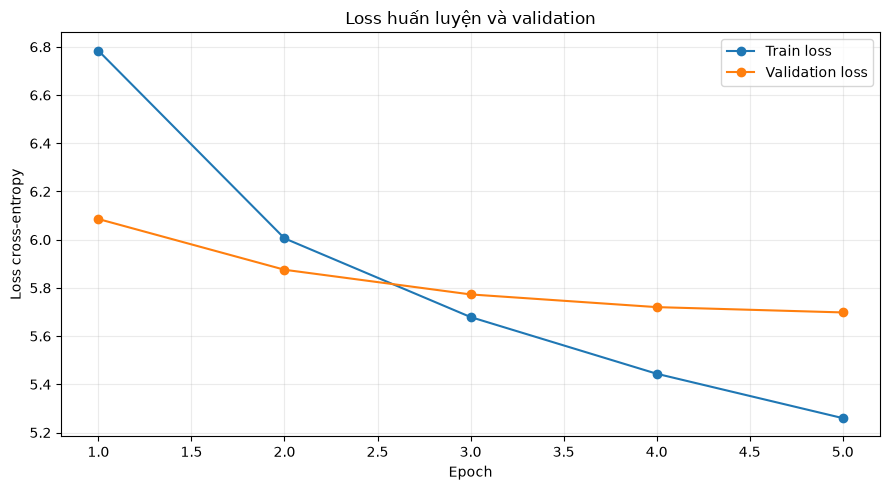

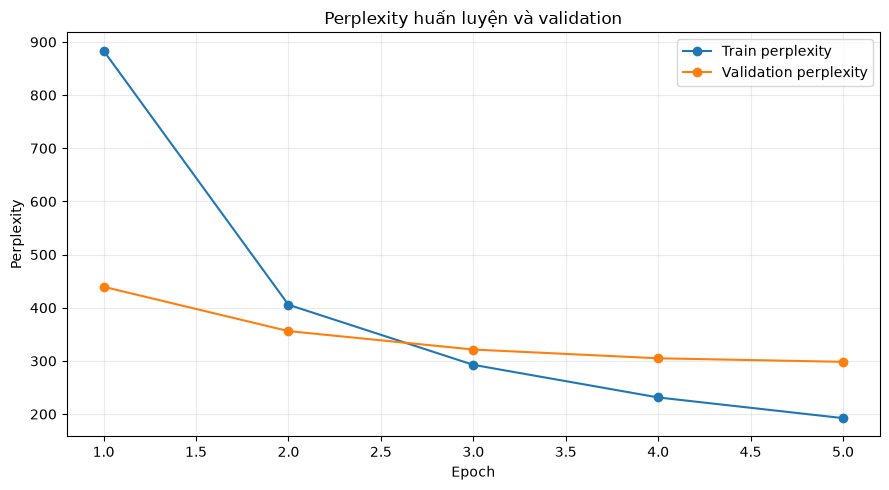

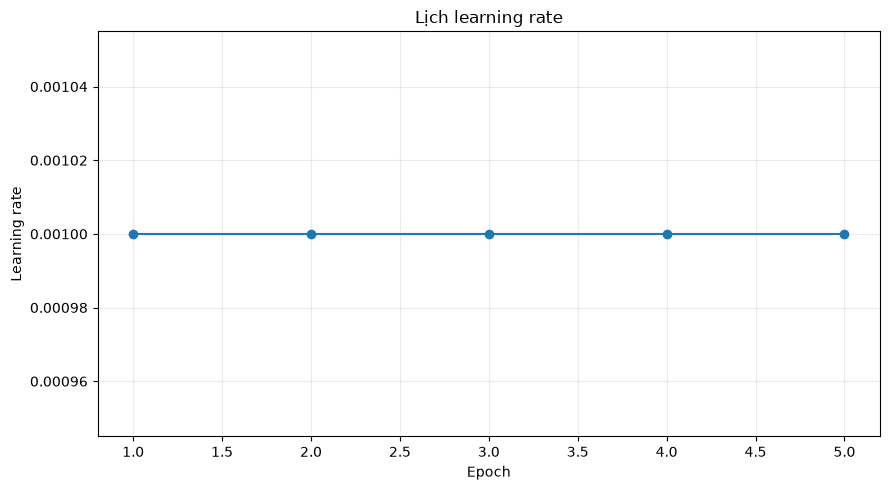

In [36]:
# Mục đích: Vẽ training loss, validation loss, perplexity và learning-rate schedule.
def plot_history(history):
    """
    Mục đích:
        Trực quan hóa quá trình học để phát hiện underfitting hoặc overfitting.
    """
    epochs = range(1, len(history['train_loss']) + 1)
    plt.figure(figsize=(9,5))
    plt.plot(epochs, history['train_loss'], marker='o', label='Train loss')
    plt.plot(epochs, history['val_loss'], marker='o', label='Validation loss')
    plt.title('Loss huấn luyện và validation')
    plt.xlabel('Epoch'); plt.ylabel('Loss cross-entropy')
    plt.legend(); plt.grid(alpha=0.25); plt.tight_layout(); plt.show()

    plt.figure(figsize=(9,5))
    plt.plot(epochs, history['train_ppl'], marker='o', label='Train perplexity')
    plt.plot(epochs, history['val_ppl'], marker='o', label='Validation perplexity')
    plt.title('Perplexity huấn luyện và validation')
    plt.xlabel('Epoch'); plt.ylabel('Perplexity')
    plt.legend(); plt.grid(alpha=0.25); plt.tight_layout(); plt.show()

    plt.figure(figsize=(9,5))
    plt.plot(epochs, history['lr'], marker='o')
    plt.title('Lịch learning rate')
    plt.xlabel('Epoch'); plt.ylabel('Learning rate')
    plt.grid(alpha=0.25); plt.tight_layout(); plt.show()

plot_history(history)

## 14. Test evaluation

Các metric chính:

- **Loss cross-entropy:** đo negative log-likelihood của target token.
- **Perplexity:** `PPL = exp(loss)`, càng thấp càng tốt trong cùng setup.
- **Top-1 accuracy:** target là token có score cao nhất.
- **Top-5 accuracy:** target nằm trong 5 candidate có score cao nhất.

Top-k accuracy đặc biệt hữu ích cho language modeling vì nhiều từ có thể là continuation hợp lý của cùng một context.

In [37]:
# Mục đích: Tính loss, perplexity và top-k accuracy trên một split.
def evaluate_language_model(model, loader, criterion, device, top_k=5):
    """
    Mục đích:
        Đánh giá RNN language model trên validation hoặc test data.

    Tham số:
        model: model cần đánh giá.
        loader: DataLoader của split.
        criterion: CrossEntropyLoss.
        device: CPU/GPU device.
        top_k: số candidate dùng cho top-k accuracy.

    Giá trị trả về:
        dict: loss, perplexity, top1_accuracy và top5_accuracy.
    """
    model.eval()
    total_loss = 0.0
    total_tokens = 0
    top1_correct = 0
    topk_correct = 0

    with torch.no_grad():
        for inputs, targets in loader:
            inputs, targets = inputs.to(device), targets.to(device)
            # Forward ở chế độ evaluation, không tạo gradient graph.
            logits, _ = model(inputs)
            flat_logits = logits.reshape(-1, logits.size(-1))
            flat_targets = targets.reshape(-1)
            loss = criterion(flat_logits, flat_targets)

            n = flat_targets.numel()
            total_loss += loss.item() * n
            total_tokens += n
            # Candidate cao nhất là top-1 prediction.
            top1_correct += (flat_logits.argmax(dim=-1) == flat_targets).sum().item()
            # Kiểm tra target có nằm trong top-k candidate hay không.
            topk = flat_logits.topk(top_k, dim=-1).indices
            topk_correct += (topk == flat_targets.unsqueeze(-1)).any(dim=-1).sum().item()

    mean_loss = total_loss / total_tokens
    return {
        'loss': float(mean_loss),
        'perplexity': loss_to_perplexity(mean_loss),
        'top1_accuracy': float(top1_correct / total_tokens),
        'top5_accuracy': float(topk_correct / total_tokens)
    }

test_metrics = evaluate_language_model(model, test_loader, criterion, DEVICE)
display(pd.DataFrame([test_metrics]))

,loss,perplexity,top1_accuracy,top5_accuracy
0,5.651778,284.797297,0.196026,0.378551


## 15. Tỷ lệ token không xác định

Do vocabulary bị giới hạn, một số word trở thành `<unk>`. Tỷ lệ này cần được báo cáo vì nó ảnh hưởng trực tiếp đến interpretation của kết quả.

Trade-off:

```text
coverage ↔ vocabulary size ↔ model size ↔ CPU time
```

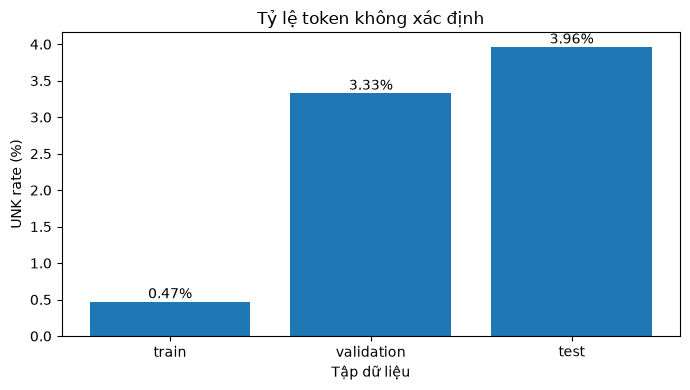

In [38]:
# Mục đích: Trực quan hóa tỷ lệ unknown token trong ba split.
def plot_unk_rates(rates):
    """Mục đích: So sánh tỷ lệ <unk> giữa train, validation và test."""
    names = list(rates.keys())
    values = [rates[n] * 100 for n in names]
    plt.figure(figsize=(7,4))
    bars = plt.bar(names, values)
    for bar, value in zip(bars, values):
        plt.text(bar.get_x()+bar.get_width()/2, bar.get_height(), f'{value:.2f}%', ha='center', va='bottom')
    plt.title('Tỷ lệ token không xác định')
    plt.xlabel('Tập dữ liệu'); plt.ylabel('UNK rate (%)')
    plt.tight_layout(); plt.show()

plot_unk_rates(unk_rates)

# Phần F — Demo tương tác

## 16. Next-word prediction

Inference pipeline:

```text
Seed text → token IDs → Embedding → RNN → last-step logits
                         ↓
                  temperature scaling
                         ↓
                      Softmax
                         ↓
                     Top-k words
```

Model không trực tiếp output một string. Model output là probability distribution trên vocabulary; từ hiển thị là token có xác suất cao nhất hoặc nằm trong top-k.

In [39]:
# Mục đích: Dự đoán top-k từ tiếp theo cho seed text.
def tokenize_seed(text):
    """Mục đích: Tách seed text thành token theo preprocessing của WikiText."""
    return text.strip().split()

def predict_next_words(model, text, top_k=10, temperature=1.0):
    """
    Mục đích:
        Tạo top-k candidate words và probability cho vị trí kế tiếp.

    Tham số:
        model: RNN language model đã train.
        text: seed text.
        top_k: số candidate hiển thị.
        temperature: tham số điều chỉnh độ phẳng probability distribution.

    Giá trị trả về:
        list[tuple[str, float]]: token và xác suất.
    """
    model.eval()
    tokens = tokenize_seed(text)
    if not tokens:
        raise ValueError('Seed text không được rỗng.')

    # Chỉ giữ context gần nhất trong giới hạn sequence length.
    context = tokens[-SEQ_LEN:]
    ids = torch.tensor([[token_to_id.get(t, token_to_id['<unk>']) for t in context]], dtype=torch.long, device=DEVICE)

    with torch.no_grad():
        # Forward toàn bộ context và lấy output ở timestep cuối.
        logits, _ = model(ids)
        last_logits = logits[:, -1, :]
        # Temperature được áp dụng trước softmax để thay đổi độ phẳng distribution.
        probs = torch.softmax(last_logits / max(temperature, 1e-6), dim=-1)
        top_probs, top_ids = torch.topk(probs, k=min(top_k, probs.size(-1)), dim=-1)

    return [(id_to_token[int(i)], float(p)) for p,i in zip(top_probs[0], top_ids[0])]


,next_word,probability
0,the,0.410530
1,a,0.053263
2,his,0.016749
3,their,0.010178
4,an,0.008362
5,its,0.008342
6,this,0.007392
7,which,0.007119
8,her,0.006848
9,"""",0.004290


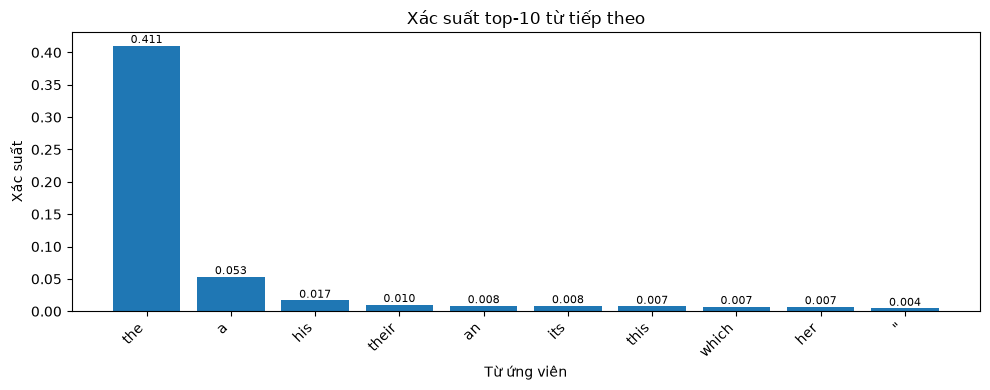

,next_word,probability
0,the,0.410530
1,a,0.053263
2,his,0.016749
3,their,0.010178
4,an,0.008362
5,its,0.008342
6,this,0.007392
7,which,0.007119
8,her,0.006848
9,"""",0.004290


In [40]:
# Mục đích: Hiển thị top-k next-word prediction bằng bảng và biểu đồ.
def show_next_word_predictions(model, text, top_k=10, temperature=1.0):
    """
    Mục đích:
        Chạy inference và trực quan hóa probability của các candidate hàng đầu.
    """
    rows = predict_next_words(model, text, top_k, temperature)
    df = pd.DataFrame(rows, columns=['next_word','probability'])
    display(df)

    plt.figure(figsize=(10,4))
    bars = plt.bar(df['next_word'], df['probability'])
    for bar, value in zip(bars, df['probability']):
        plt.text(bar.get_x()+bar.get_width()/2, bar.get_height(), f'{value:.3f}', ha='center', va='bottom', fontsize=8)
    plt.title(f'Xác suất top-{top_k} từ tiếp theo')
    plt.xlabel('Từ ứng viên'); plt.ylabel('Xác suất')
    plt.xticks(rotation=45, ha='right'); plt.tight_layout(); plt.show()
    return df

# Seed này có thể thay đổi trực tiếp khi thuyết trình.
show_next_word_predictions(model, 'the history of', top_k=10, temperature=1.0)


## 17. Temperature experiment

Temperature được áp dụng trước softmax:

\[P_i = softmax(z_i/T)\]

- `T < 1`: distribution sắc hơn, model tập trung mạnh vào candidate cao nhất.
- `T = 1`: distribution gốc.
- `T > 1`: distribution phẳng hơn, nhiều candidate có probability đáng kể hơn.

Temperature chỉ tác động ở inference time và không làm thay đổi model parameters.


Temperature = 0.5


,next_word,probability
0,the,0.978121
1,a,0.016465
2,his,0.001628
3,their,0.000601
4,an,0.000406
5,its,0.000404
6,this,0.000317
7,which,0.000294


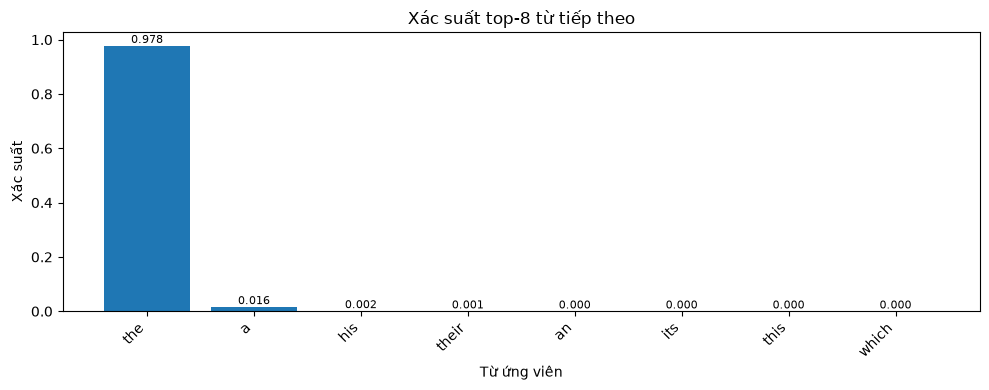


Temperature = 1.0


,next_word,probability
0,the,0.410530
1,a,0.053263
2,his,0.016749
3,their,0.010178
4,an,0.008362
5,its,0.008342
6,this,0.007392
7,which,0.007119


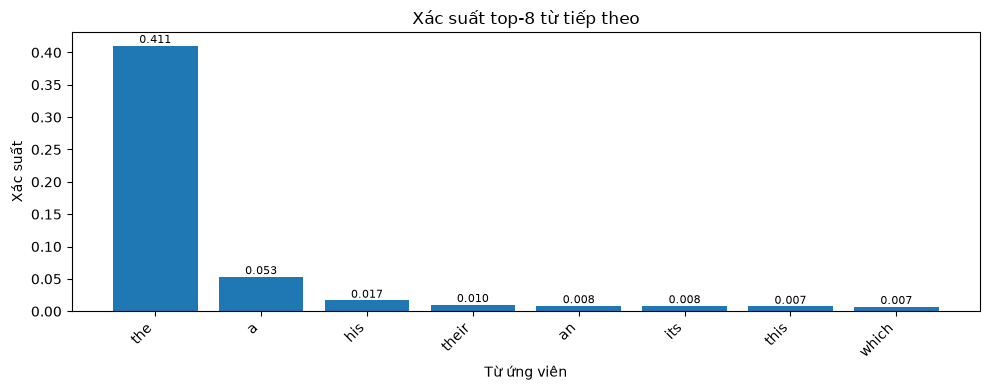


Temperature = 1.5


,next_word,probability
0,the,0.040576
1,a,0.010399
2,his,0.004809
3,their,0.003450
4,an,0.003026
5,its,0.003022
6,this,0.002788
7,which,0.002719


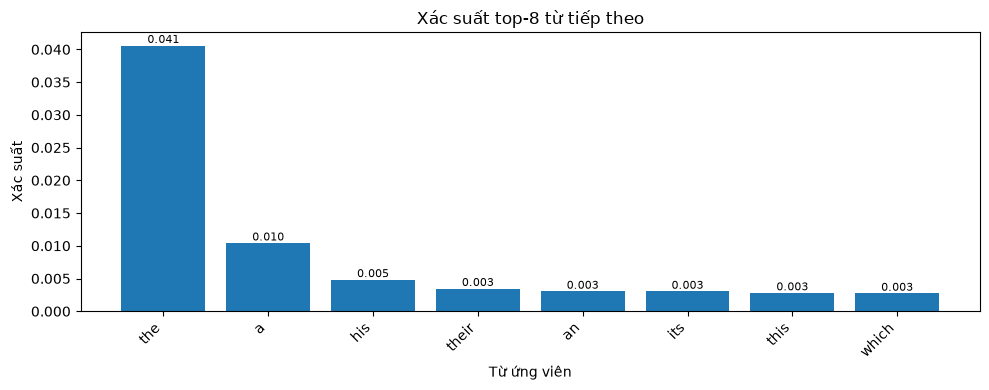

In [41]:
# Mục đích: So sánh probability distribution khi thay đổi temperature.
for temperature in [0.5, 1.0, 1.5]:
    print(f'\nTemperature = {temperature}')
    show_next_word_predictions(model, 'the history of', top_k=8, temperature=temperature)


## 18. Autoregressive continuation

Có thể lặp lại next-word prediction bằng cách đưa token vừa dự đoán trở lại model:

```text
seed → predict → append → predict → append → ...
```

Đây là autoregressive text generation. Với vanilla RNN nhỏ chạy CPU, mục tiêu là minh họa cơ chế sequence prediction chứ không cạnh tranh với LLM hiện đại.

In [42]:
# Mục đích: Sinh tiếp văn bản bằng autoregressive sampling.
def generate_text(model, seed_text, num_words=30, temperature=0.8):
    """
    Mục đích:
        Sinh tiếp một đoạn text bằng cách lặp lại dự đoán token kế tiếp.

    Tham số:
        model: RNN language model.
        seed_text: đoạn text ban đầu.
        num_words: số token mới cần sinh.
        temperature: mức ngẫu nhiên của sampling.

    Giá trị trả về:
        str: seed text cộng continuation được sinh.
    """
    generated = tokenize_seed(seed_text)

    for _ in range(num_words):
        context = generated[-SEQ_LEN:]
        ids = torch.tensor([[token_to_id.get(t, token_to_id['<unk>']) for t in context]], dtype=torch.long, device=DEVICE)

        with torch.no_grad():
            # Chỉ dùng distribution tại timestep cuối.
            logits, _ = model(ids)
            probs = torch.softmax(logits[:, -1, :] / max(temperature, 1e-6), dim=-1)
            # Sampling giúp tạo continuation đa dạng.
            next_id = torch.multinomial(probs, 1).item()

        generated.append(id_to_token[next_id])

    return ' '.join(generated)

print(generate_text(model, 'the history of', num_words=30, temperature=0.8))


the history of the witch ports in which he became Carey as the urban National hats ( <unk> ) that included a long @-@ party group , Applewhite . In an interview ,


In [43]:
# Mục đích: Export training history và test metrics cho Flask web demo.
from pathlib import Path
import json

WEB_METRICS_DIR = Path(METRICS_DIR)
WEB_METRICS_DIR.mkdir(parents=True, exist_ok=True)

with open(WEB_METRICS_DIR / "training_history.json", "w", encoding="utf-8") as f:
    json.dump(history, f, indent=2)

with open(WEB_METRICS_DIR / "test_metrics.json", "w", encoding="utf-8") as f:
    json.dump(test_metrics, f, indent=2)

print("Web demo artifacts exported to:", WEB_METRICS_DIR)

Web demo artifacts exported to: C:\Users\ADMIN\Downloads\Intelligent System\RNN\DATA\Not Plus\outputs\metrics
